# MAKRO 2026 in ModelFlow: the input-output system of the baseline

This notebook shows the input-output (IO) system of MAKRO with the charts in `tools-io\io_viz.py`: where each
sector's production goes, how much of each demand component is imported, and how that changes over the horizon.

It reads `data\makro26_baseline.pcimz`, the model and the baseline saved by `makro26_all_shocks.ipynb`
(section 8) without the kept shock solutions. Nothing is solved: everything shown is in the file.

It needs ModelFlow from `C:\modelflow2\modelflow` and `plotly` (both in `book314b`). The structure graph at the
end uses Graphviz's `dot` program.

In [1]:
import sys, subprocess
import pandas as pd
from IPython.display import HTML, display
from modelclass import model
sys.path.insert(0, r'C:\mfmodeller_raw\makro\makro26\tools-io')
import io_viz
pd.set_option('display.max_colwidth', 120, 'display.max_rows', 200)

## 1. The model and the baseline

The load takes a few seconds: the file was saved from a model loaded with `straight=True`, so the analysis of the
simultaneous structure is skipped (see `makro26_all_shocks.ipynb`).

In [2]:
mmakro, baseline = model.modelload(r'C:\mfmodeller_raw\makro\makro26\data\makro26_baseline.pcimz')
print('Kept solutions in the file:', list(mmakro.keep_solutions) or 'none')
print(f'Data {baseline.index[0]}-{baseline.index[-1]}, the model is solved for {mmakro.current_per[0]}-{mmakro.current_per[-1]}')

Feather/zip file read: C:\mfmodeller_raw\makro\makro26\data\makro26_baseline.pcimz
Model: MAKRO 2026-September (DREAM) in ModelFlow, baseline
Kept solutions in the file: none
Data 2015-2131, the model is solved for 2030-2129


## 2. From the ModelFlow names to the IO table

In MAKRO the IO system is `qIOy[d,s]` (deliveries from domestic production in sector `s` to the demand component
`d`) and `qIOm[d,s]` (imports of the goods of sector `s` to `d`), with prices `pIOy`, `pIOm` and values `vIOy`,
`vIOm`. In the translation they are `QIOY__CVAR__TJE`, `VIOM__IM__FRE` and so on.

`io_viz.extract_io` reads them into a long table `year | d | s | origin | value` (origin `dom` or `imp`). Two
things are adjusted for MAKRO's naming:

- **Intermediate use.** In MAKRO the demand component for intermediate use is the name of the using sector
  (`vIOy[byg,tje]`: services used by construction). `io_viz` expects these as `r` + sector (`rByg`), so
  `d_name` renames them. Then `io_viz` puts them in the group *Intermediate* and finds the user sector for the
  import content.
- **Totals.** The values also exist for sums (`CTOT`, `ITOT`, `XTOT`, `DTOT`, `TOT`). These are left out, so
  that nothing is counted twice.

The charts use the **values** (`vIOy`, `vIOm`, billion kr. in current prices): values add up across cells and
the import content needs them. The volumes are in `io_q` if you want them.

In [3]:
SECTORS = set(io_viz.SECTOR_LABELS)          # off tje fre byg ene udv lan soe bol


def d_name(code):
    '''MAKRO demand component in upper case -> io_viz name: CVAR -> cVar, BYG (intermediate use) -> rByg.'''
    code = code.lower()
    return 'r' + code.capitalize() if code in SECTORS else code[0] + code[1:].capitalize()


def io_frame(df, kind='V'):
    '''The long IO table of a ModelFlow dataframe. kind: V (values), Q (volumes) or P (prices).'''
    tidy = io_viz.extract_io(df,
                             pattern_dom=rf'^{kind}IOY__(?P<d>[A-Z0-9]+)__(?P<s>[A-Z0-9]+)$',
                             pattern_imp=rf'^{kind}IOM__(?P<d>[A-Z0-9]+)__(?P<s>[A-Z0-9]+)$',
                             d_case=d_name)
    totals = tidy['d'].str.lower().str.endswith('tot') | (tidy['s'] == 'tot')
    return tidy[~totals].reset_index(drop=True)


io_v = io_frame(baseline)          # values
io_q = io_frame(baseline, 'Q')     # volumes
print(f"{io_v['d'].nunique()} demand components, {io_v['s'].nunique()} sectors, "
      f"{io_v.groupby(['d', 's', 'origin']).ngroups} cells with data")

24 demand components, 9 sectors, 432 cells with data


The demand components and the sectors, with their size in the first year of the run. The descriptions of the
demand components are in `io_viz.DEMAND_LABELS`; in all the charts below they show when the mouse is over a
demand component.

In [4]:
D_LABELS = io_viz.DEMAND_LABELS          # the descriptions of the demand components, defined in io_viz

first = int(mmakro.current_per[0])
v = io_v[io_v['year'] == first].pivot_table(index='d', columns='origin', values='value', aggfunc='sum').fillna(0)
v['total'] = v.sum(axis=1)
v['import share, %'] = 100 * v['imp'] / v['total'].where(v['total'] != 0)
v.insert(0, 'group', [io_viz.default_group(d) for d in v.index])
v.insert(0, 'label', [D_LABELS.get(d, '') for d in v.index])
v = v.sort_values(['group', 'total'], ascending=[True, False])
display(v.style.format({'dom': '{:,.1f}', 'imp': '{:,.1f}', 'total': '{:,.1f}', 'import share, %': '{:.1f}'})
         .set_caption(f'Demand components {first}, billion kr.'))

s = io_v[io_v['year'] == first].pivot_table(index='s', columns='origin', values='value', aggfunc='sum').fillna(0)
s.index = [f'{x} ({io_viz.SECTOR_LABELS[x]})' for x in s.index]
s.columns = ['deliveries from domestic production', 'imports of the goods of the sector']
s.style.format('{:,.1f}').set_caption(f'Sectors {first}, billion kr.')

origin,label,group,dom,imp,total,"import share, %"
d,,,,,,
cTje,Consumption of services,Consumption,472.9,31.4,504.3,6.2
cVar,Consumption of goods,Consumption,318.6,136.4,455.1,30.0
cBol,Consumption of housing,Consumption,275.4,1.2,276.6,0.4
cEne,Consumption of energy,Consumption,90.9,10.9,101.9,10.7
cTur,Residents' tourism abroad,Consumption,0.0,61.4,61.4,100.0
cBil,Consumption of cars,Consumption,19.9,39.7,59.6,66.7
xVar,Exports of goods,Exports,870.2,295.8,"1,166.0",25.4
xTje,Exports of services,Exports,383.6,19.8,403.4,4.9
xSoe,Exports of shipping,Exports,299.4,8.9,308.3,2.9


,deliveries from domestic production,imports of the goods of the sector
bol (Housing),252.8,0.0
byg (Construction),447.5,0.0
ene (Energy supply),210.4,102.4
fre (Manufacturing),"1,114.5",903.9
lan (Agriculture),140.7,0.0
off (Public),812.2,0.0
soe (Shipping),303.6,198.8
tje (Services),"2,574.2",704.4
udv (Extraction),31.6,25.2


Note: the domestic deliveries of a sector add up to a little more than its production value `vY` (services
2 574 against 2 414 billion kr. in 2030); the IO cells are valued at their own prices `pIOy`. The import content
in section 6 uses the IO cells only, so it is consistent in itself.

## 3. Settings

In [5]:
year = 2030                                   # the year of the one-year charts
years = [2030, 2040, 2050, 2075, 2100, 2129]  # the years of the slider
min_flow = 1.0                                # flows smaller than this (billion kr.) are left out of the Sankeys

## 4. Where production goes: Sankey diagrams

From the sectors and imports (left) to the demand components (right). The width of a band is the value of the
flow. All imports are one node; `merge_imports=False` splits them by the sector of the goods.

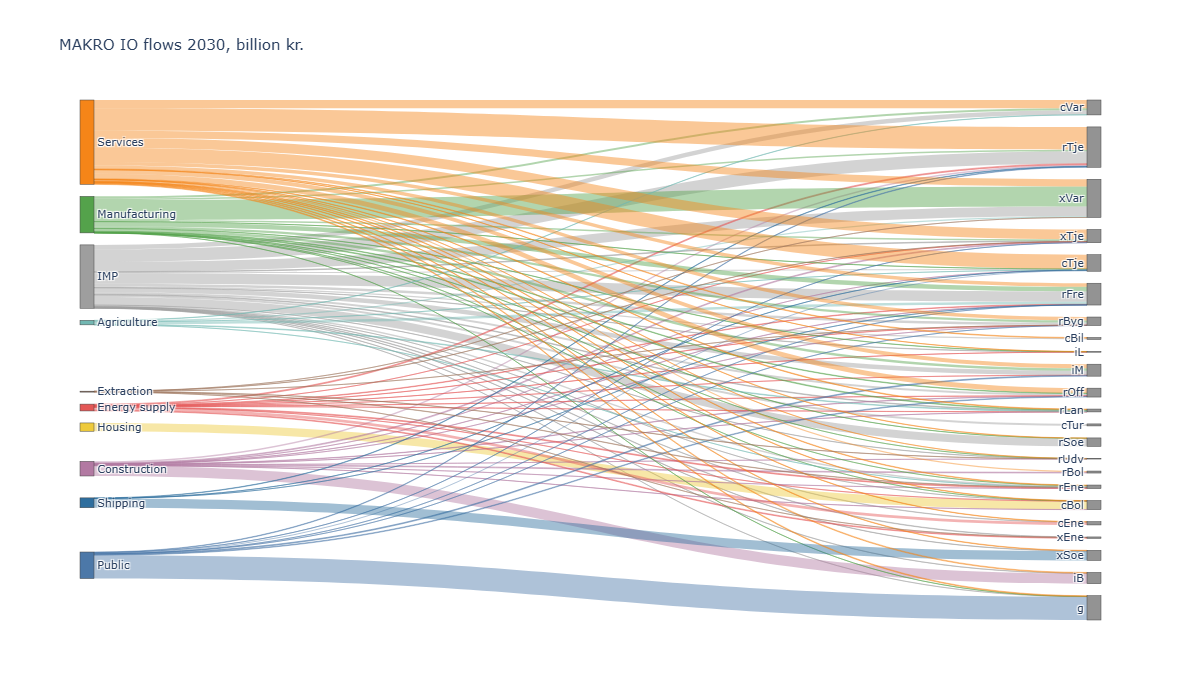

In [6]:
io_viz.sankey(io_v, year, min_flow=min_flow, title=f'MAKRO IO flows {year}, billion kr.')

With a third column, the aggregates (consumption, public consumption, investment, exports). Intermediate use
is left out so that only final demand is shown.

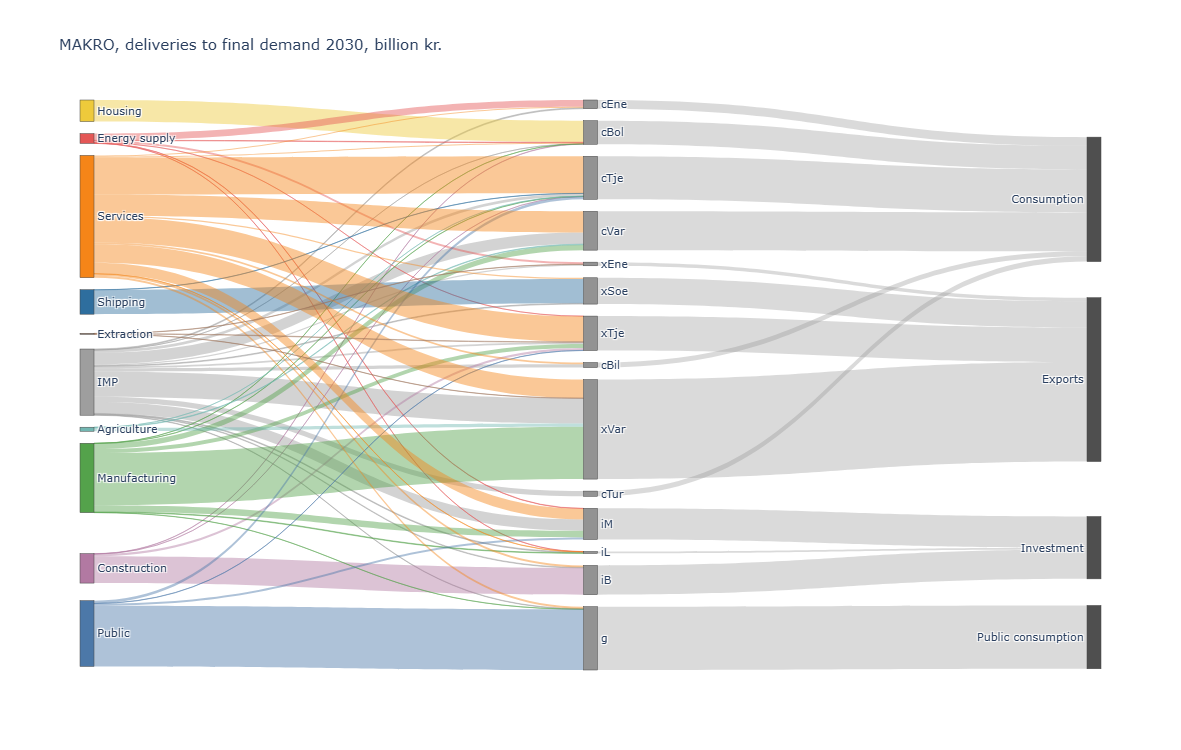

In [7]:
io_viz.sankey3(io_v, year, min_flow=min_flow, include_intermediate=False,
               title=f'MAKRO, deliveries to final demand {year}, billion kr.')

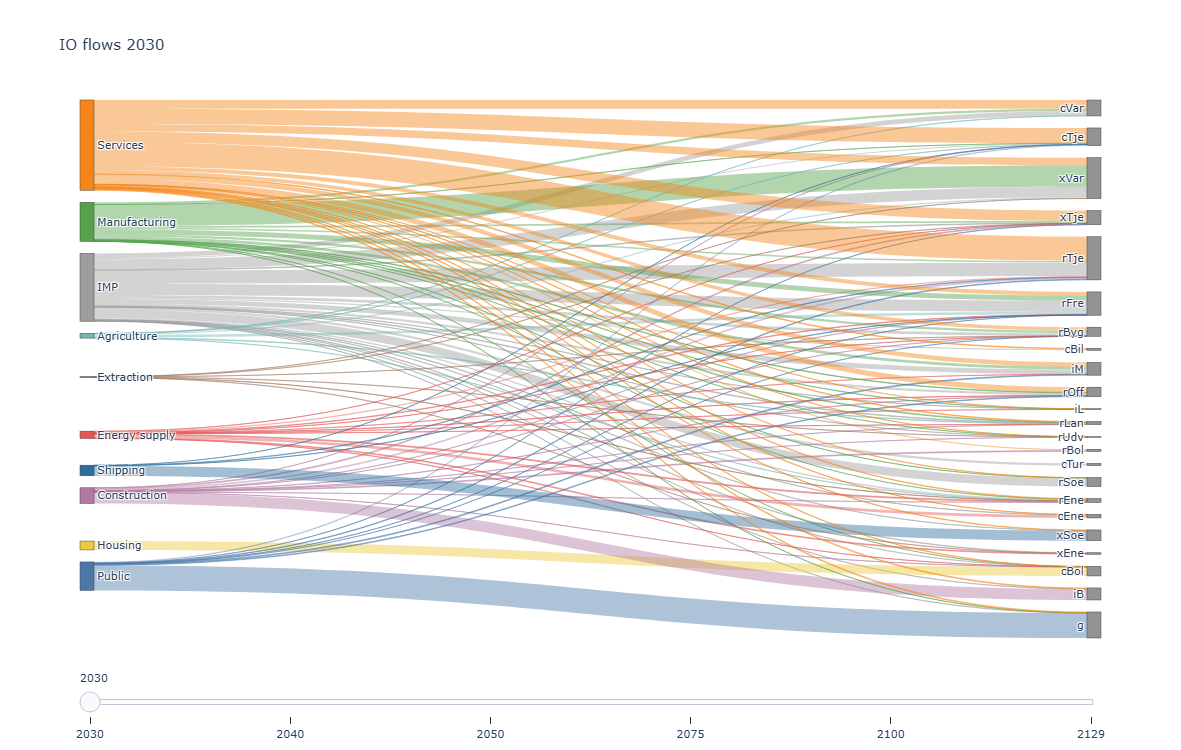

In [8]:
io_viz.sankey_years(io_v, years, min_flow=min_flow)

## 5. The IO matrix

Rows are the demand components, columns the sectors the goods come from. First the total (domestic plus
imports), then the import share of each cell.

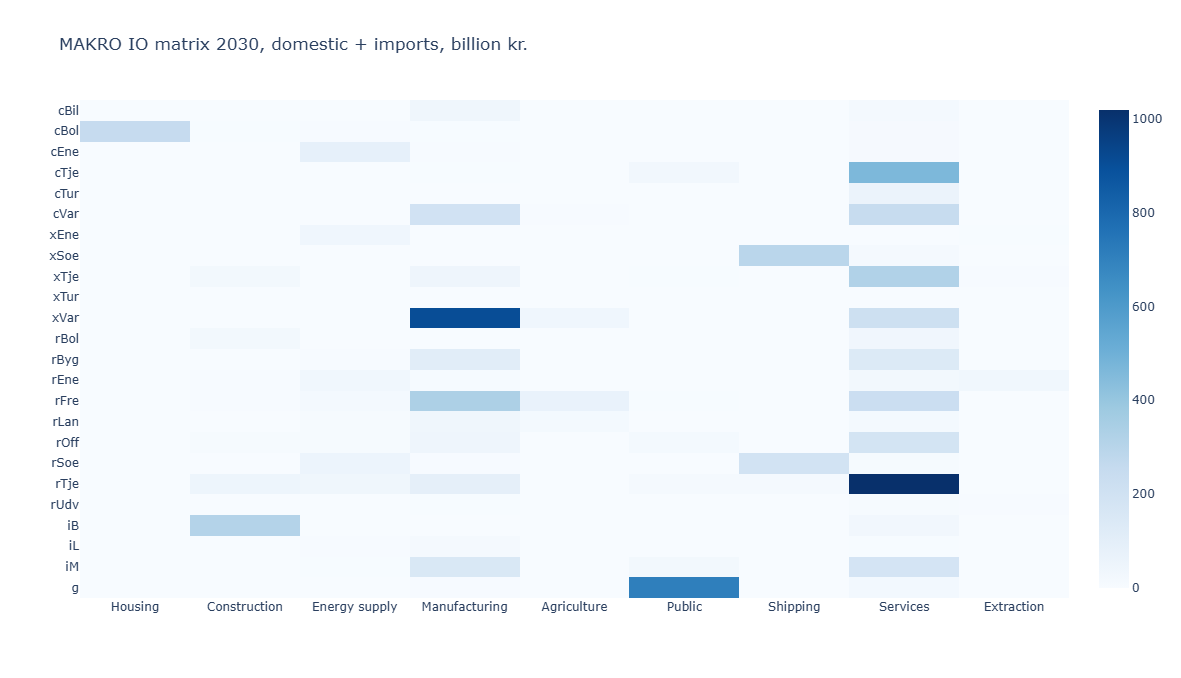

In [9]:
io_viz.heatmap(io_v, year, metric='total', title=f'MAKRO IO matrix {year}, domestic + imports, billion kr.')

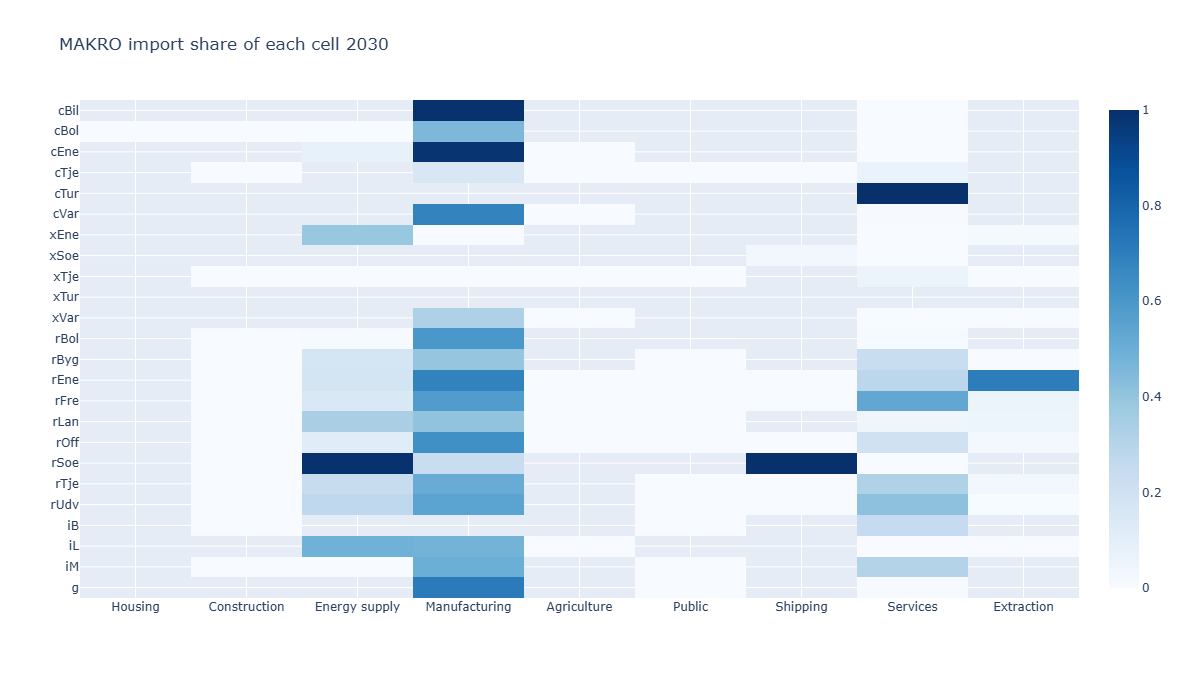

In [10]:
io_viz.heatmap(io_v, year, metric='import_share', title=f'MAKRO import share of each cell {year}')

How the import shares change over the baseline: the share in the last year minus the share in the first year
(0.05 = 5 percentage points). The big changes are in the column for extraction (`udv`): oil and gas
extraction in the North Sea is phased out in the baseline, so the extraction goods used in Denmark end up almost
all imported.

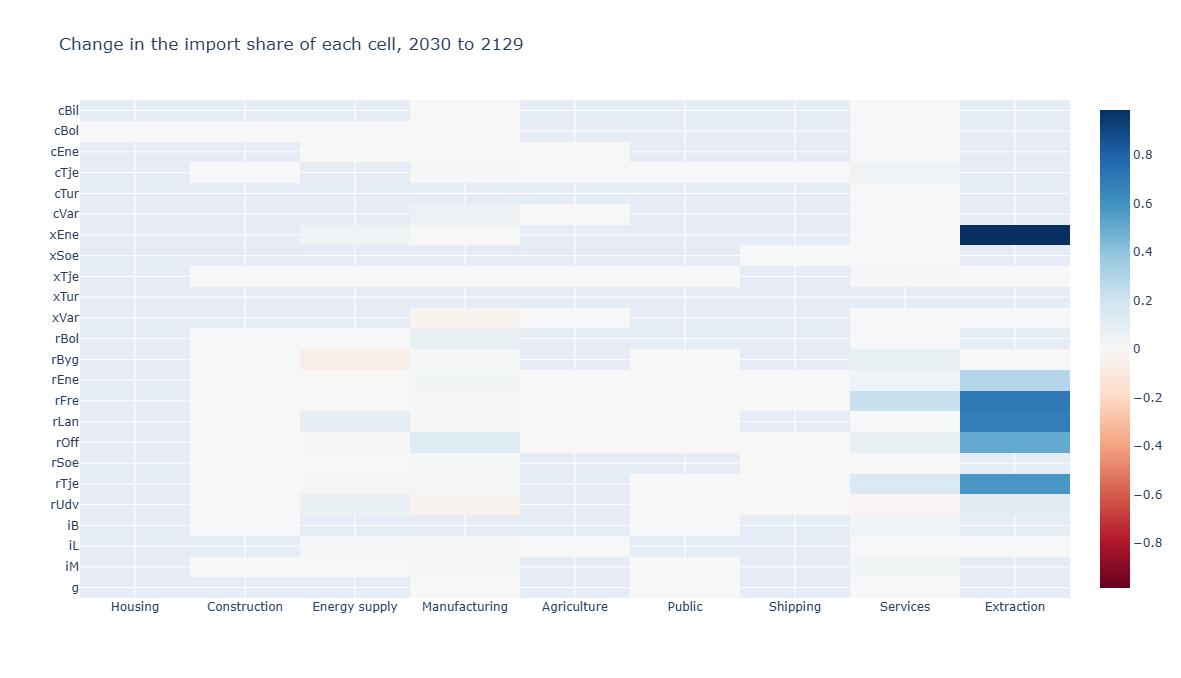

In [11]:
last = int(mmakro.current_per[-1])
io_viz.heatmap(io_v, last, metric='import_share', base=io_v, base_year=first,
               title=f'Change in the import share of each cell, {first} to {last}')

## 6. Import content of final demand

The direct import share of a demand component is the imports delivered to it. The indirect share is the
imports used in the domestic production delivered to it, through all rounds of intermediate use (the Leontief
inverse of the domestic intermediate deliveries).

,label,total,direct_share,indirect_share,import_content
d,,,,,
cTur,Residents' tourism abroad,61.4,1.000,0.000,1.000
xSoe,Exports of shipping,308.3,0.029,0.770,0.798
cBil,Consumption of cars,59.6,0.667,0.078,0.745
iL,Change in inventories,24.1,0.381,0.202,0.583
xEne,Exports of energy,42.7,0.360,0.192,0.552
iM,Investment in machinery,366.0,0.363,0.174,0.537
xVar,Exports of goods,"1,166.0",0.254,0.254,0.508
cVar,Consumption of goods,455.1,0.300,0.185,0.484
cEne,Consumption of energy,101.9,0.107,0.256,0.363


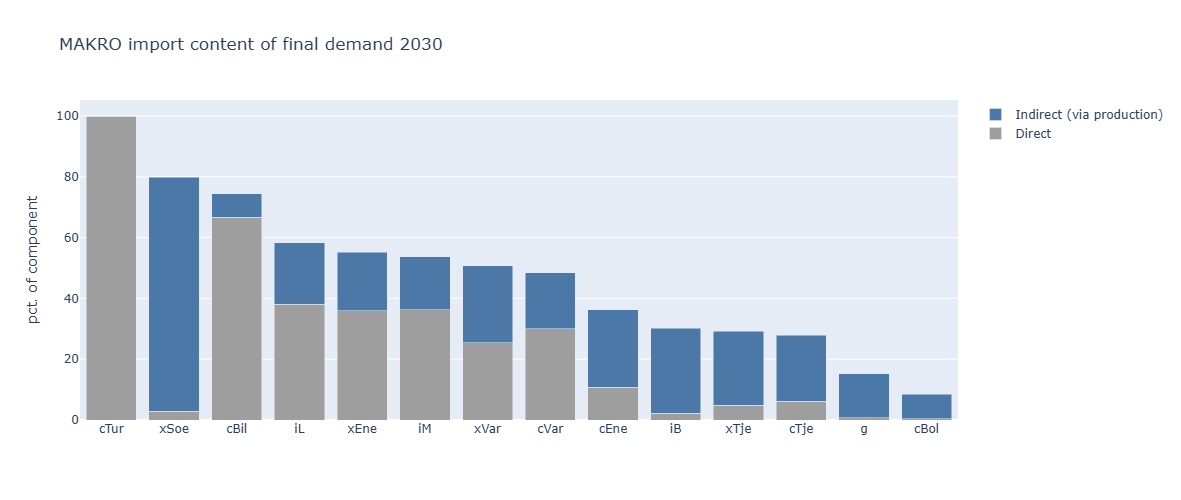

In [12]:
ic = io_viz.import_content(io_v, year)
ic = ic[ic['total'] > 0]                                   # foreign tourists' spending is zero in the IO table
ic.insert(0, 'label', [D_LABELS.get(d, '') for d in ic.index])
display(ic.style.format({'total': '{:,.1f}', 'direct_share': '{:.3f}', 'indirect_share': '{:.3f}', 'import_content': '{:.3f}'})
          .set_caption(f'Import content {year} (total in billion kr.)'))
io_viz.import_content_bar(ic, title=f'MAKRO import content of final demand {year}')

## 7. Where each sector's output goes

One panel per sector: the share of its domestic deliveries that goes to each demand component.

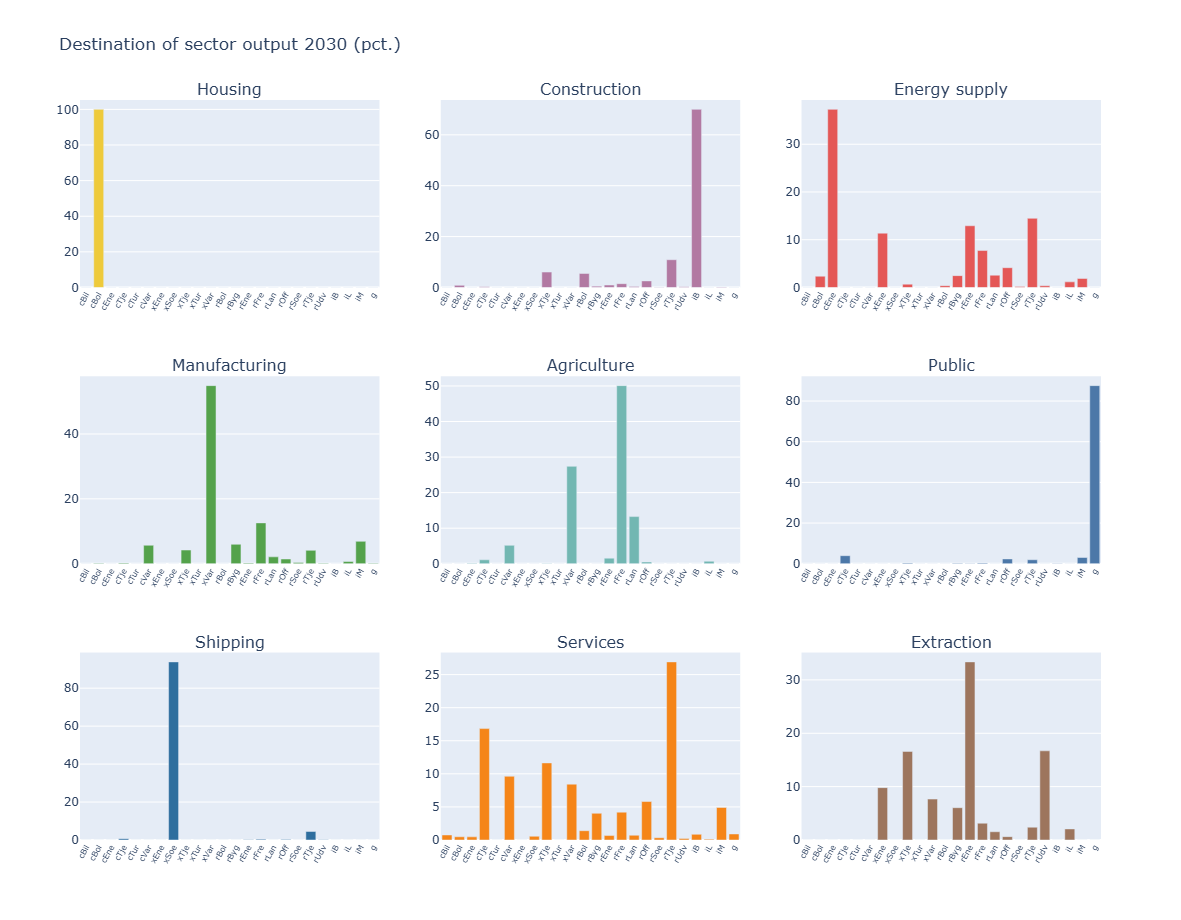

In [13]:
io_viz.small_multiples(io_v, year, cols=3)

## 8. The structure as a graph

Sectors (boxes) deliver to demand components (ellipses); the width of an edge is the value of the flow. The
dashed edges close the loop: intermediate use `rX` is demand from sector `X`. Flows below `graph_min` billion
kr. are left out. The graph runs from left to right, so the picture is tall; each demand component has its
description under the code. The mouse over a node or an edge shows the flow.

In [16]:
graph_min = 20
dot = io_viz.structure_graph(io_v, year, min_flow=graph_min, rankdir='LR')   # LR: tall picture; 'TB' a wide one
svg = subprocess.run(['dot', '-Tsvg'], input=dot, capture_output=True, encoding='utf-8', check=True, timeout=120).stdout
display(HTML(svg[svg.index('<svg'):]))           # inline svg, so the tooltips work

## Next: the shocks

The same frames can be made from a shock solution, `io_frame(solution)`, for example from the kept solutions in
`data\makro26_shocks.pcimz` (`mshocks.keep_solutions[...]`).
Then `io_viz.shock_heatmap`, `io_viz.shock_sankey` and `io_viz.price_contributions` /
`price_passthrough_bar` (with the changes in `PY__<s>` and `PM__<s>`) show the effect of the shock on the IO
system.